# Formula 1 Podium Prediction — Milestone 1

Predict whether a driver finishes in the top three using information available after qualifying and before the race. Each modeling row represents one driver in one race.

This section inspects and cleans the source data. Missing model inputs will be handled later using training data only.

## 1. Data Inspection and Cleaning

### 1.1 Load the data without changing the originals

Import the libraries and load all 14 CSV files. Keep missing-value markers unchanged so we can count them, and store the original tables in `raw_tables` for comparison.


In [2]:
# Path helps us locate dataset files.
from pathlib import Path

# Pandas handles tables; NumPy supports numerical operations.
import pandas as pd
import numpy as np

# These libraries will help us visualize the data.
import matplotlib.pyplot as plt
import seaborn as sns

# Show all columns when displaying a small table.
pd.set_option("display.max_columns", None)

# Use a consistent appearance for our plots.
sns.set_theme(style="whitegrid")

# We will reuse this seed for reproducible random operations.
RANDOM_STATE = 42

In [3]:
# The folder containing the 14 Formula 1 CSV files.
data_folder = Path(
    "/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020"
)

# Load each CSV into a dictionary using its filename as the key.
# Keep missing-value placeholders unchanged for our initial audit.
raw_tables = {}

for file in sorted(data_folder.glob("*.csv")):
    raw_tables[file.stem] = pd.read_csv(file, keep_default_na=False)

# Show the number of rows and columns in each table.
table_summary = pd.DataFrame([
    {
        "Table": name,
        "Rows": table.shape[0],
        "Columns": table.shape[1]
    }
    for name, table in raw_tables.items()
])

print("Number of tables loaded:", len(raw_tables))
display(table_summary)

Number of tables loaded: 14


,Table,Rows,Columns
0,circuits,77,9
1,constructor_results,12625,5
2,constructor_standings,13391,7
3,constructors,212,5
4,driver_standings,34863,7
5,drivers,861,9
6,lap_times,589081,6
7,pit_stops,11371,7
8,qualifying,10494,9
9,races,1125,18


### 1.2 Check which seasons have results

The dataset name may not reflect its full coverage. Count listed races and races with at least one result per year; this does not verify every individual entry. The saved output covers 1950–2024.


In [4]:
# Use the raw tables for inspection without changing them.
races_raw = raw_tables["races"]
results_raw = raw_tables["results"]

# Find which races have at least one recorded result.
race_has_results = races_raw["raceId"].isin(results_raw["raceId"])

# Create a separate table summarizing coverage for each season.
season_coverage = (
    races_raw.assign(has_results=race_has_results)
    .groupby("year")
    .agg(
        races_listed=("raceId", "nunique"),
        races_with_results=("has_results", "sum")
    )
    .reset_index()
)

print("Earliest season listed:", races_raw["year"].min())
print("Latest season listed:", races_raw["year"].max())

# Check the latest season represented in the results table.
print(
    "Latest season with results:",
    races_raw.loc[race_has_results, "year"].max()
)

# Display recent seasons to check the assignment's required coverage.
display(season_coverage.tail(12))

Earliest season listed: 1950
Latest season listed: 2024
Latest season with results: 2024


,year,races_listed,races_with_results
63,2013,19,19
64,2014,19,19
65,2015,19,19
66,2016,21,21
67,2017,20,20
68,2018,21,21
69,2019,21,21
70,2020,17,17
71,2021,22,22
72,2022,22,22


### 1.3 Find missing values before cleaning

Missing data can appear as `\N`, empty text, or an actual null. Count all three forms and plot the most affected columns before deciding how to handle them. A high missing percentage alone does not justify deleting rows.


,Table,Column,Sentinel count,Empty count,Null count,Missing count,Missing percent
13,constructor_results,status,12608,0,0,12608,99.87
81,races,sprint_time,1110,0,0,1110,98.67
80,races,sprint_date,1107,0,0,1107,98.40
77,races,fp3_time,1072,0,0,1072,95.29
73,races,fp1_time,1057,0,0,1057,93.96
75,races,fp2_time,1057,0,0,1057,93.96
79,races,quali_time,1057,0,0,1057,93.96
76,races,fp3_date,1053,0,0,1053,93.60
35,drivers,number,802,0,0,802,93.15
72,races,fp1_date,1035,0,0,1035,92.00


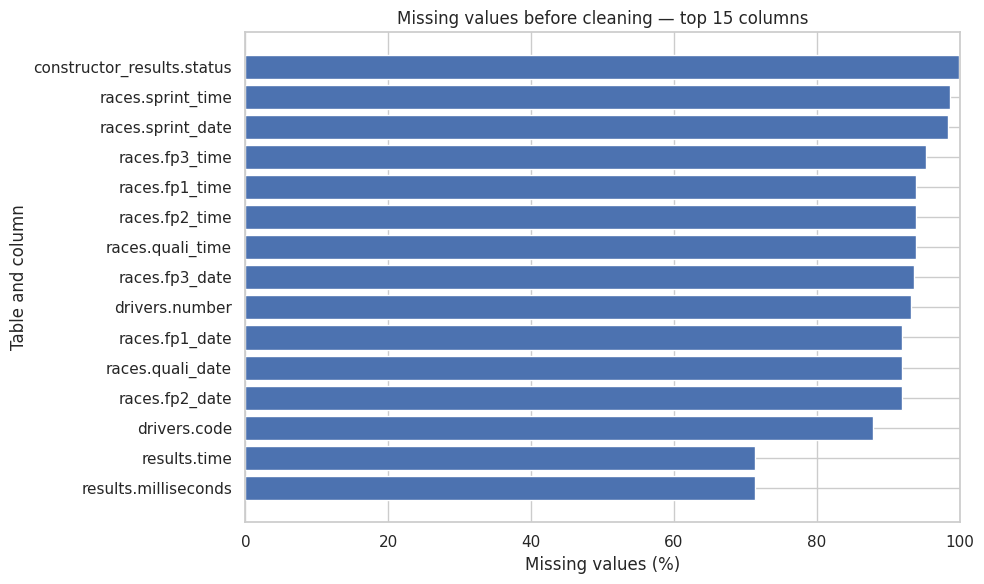

In [5]:
# Collect missing-value counts for every column in every table.
missing_records = []

for table_name, table in raw_tables.items():
    for column in table.columns:

        # These CSV files use the text \N to represent missing values.
        sentinel_count = table[column].eq("\\N").sum()

        # Empty fields were also preserved when we loaded the files.
        empty_count = table[column].eq("").sum()

        # Check for actual pandas missing values as well.
        null_count = table[column].isna().sum()

        total_missing = sentinel_count + empty_count + null_count

        missing_records.append({
            "Table": table_name,
            "Column": column,
            "Sentinel count": sentinel_count,
            "Empty count": empty_count,
            "Null count": null_count,
            "Missing count": total_missing,
            "Missing percent": (
                100 * total_missing / len(table) if len(table) > 0 else 0
            )
        })

# Save the complete audit, including columns with no missing values.
missing_audit_before = pd.DataFrame(missing_records)

# Display only affected columns, starting with the highest percentage.
missing_columns = (
    missing_audit_before[
        missing_audit_before["Missing count"] > 0
    ]
    .sort_values("Missing percent", ascending=False)
)

display(missing_columns.round(2))

# Visualize the 15 columns with the highest missing percentages.
top_missing = missing_columns.head(15)

if not top_missing.empty:
    plt.figure(figsize=(10, 6))

    plt.barh(
        top_missing["Table"] + "." + top_missing["Column"],
        top_missing["Missing percent"]
    )

    plt.gca().invert_yaxis()
    plt.xlabel("Missing values (%)")
    plt.ylabel("Table and column")
    plt.title("Missing values before cleaning — top 15 columns")
    plt.xlim(0, 100)
    plt.tight_layout()
    plt.show()

### 1.4 Give missing values one consistent format

Create `clean_tables` as copies and replace missing-value markers with `NaN`. Check that the missing counts match and every row is preserved. This standardizes missing data; it does not fill it.


In [6]:
# Create independent copies so the original tables stay unchanged.
clean_tables = {
    name: table.copy(deep=True)
    for name, table in raw_tables.items()
}

missing_check = []

for name, table in clean_tables.items():

    # Replace literal \N and empty strings with pandas missing values.
    # mask replaces only cells that match these conditions.
    placeholder_mask = table.eq("\\N") | table.eq("")
    clean_tables[name] = table.mask(placeholder_mask)

    # Get the missing count measured in our original audit.
    expected_missing = missing_audit_before.loc[
        missing_audit_before["Table"] == name,
        "Missing count"
    ].sum()

    # Pandas can now recognize the missing values using isna().
    actual_missing = clean_tables[name].isna().sum().sum()

    missing_check.append({
        "Table": name,
        "Missing before": int(expected_missing),
        "Missing after": int(actual_missing),
        "Row count unchanged": len(table) == len(raw_tables[name])
    })

missing_check = pd.DataFrame(missing_check)
display(missing_check)

# Verify that we changed the representation, not the missing count.
assert (
    missing_check["Missing before"] == missing_check["Missing after"]
).all(), "Missing counts do not match. Investigate before continuing."

assert missing_check["Row count unchanged"].all(), (
    "A table's row count changed unexpectedly."
)

print("Checks passed: missing values standardized and all rows preserved.")

,Table,Missing before,Missing after,Row count unchanged
0,circuits,0,0,True
1,constructor_results,12608,12608,True
2,constructor_standings,0,0,True
3,constructors,0,0,True
4,driver_standings,0,0,True
5,drivers,1559,1559,True
6,lap_times,0,0,True
7,pit_stops,0,0,True
8,qualifying,11668,11668,True
9,races,11349,11349,True


Checks passed: missing values standardized and all rows preserved.


### 1.5 Check IDs and repeated driver–race entries

A primary key identifies a record; it should be present and unique. We also check driver–race pairs because different result IDs can still describe the same driver in the same race. The audit found 85 repeated pairs across 176 rows.


In [7]:
# Define the column(s) that should uniquely identify each table's rows.
# Lap times and pit stops need multiple columns to identify one record.
primary_keys = {
    "circuits": ["circuitId"],
    "constructor_results": ["constructorResultsId"],
    "constructor_standings": ["constructorStandingsId"],
    "constructors": ["constructorId"],
    "driver_standings": ["driverStandingsId"],
    "drivers": ["driverId"],
    "lap_times": ["raceId", "driverId", "lap"],
    "pit_stops": ["raceId", "driverId", "stop"],
    "qualifying": ["qualifyId"],
    "races": ["raceId"],
    "results": ["resultId"],
    "seasons": ["year"],
    "sprint_results": ["resultId"],
    "status": ["statusId"]
}

key_records = []

for name, keys in primary_keys.items():
    table = clean_tables[name]

    key_records.append({
        "Table": name,
        "Key columns": ", ".join(keys),

        # Count rows missing any part of their key.
        "Rows with missing keys": int(
            table[keys].isna().any(axis=1).sum()
        ),

        # Count additional rows sharing a key with an earlier row.
        "Extra duplicate keys": int(
            table.duplicated(subset=keys).sum()
        )
    })

key_audit = pd.DataFrame(key_records)
display(key_audit)

# A unique resultId does not guarantee a unique driver–race pair.
# Our modeling table requires one row per driver in each race.
results = clean_tables["results"]

duplicate_mask = results.duplicated(
    subset=["raceId", "driverId"],
    keep=False
)

# Keep all rows involved in repeated pairs so we can inspect them.
duplicate_driver_races = (
    results.loc[duplicate_mask]
    .sort_values(["raceId", "driverId", "resultId"])
)

print(
    "\nNumber of repeated driver–race pairs:",
    duplicate_driver_races[["raceId", "driverId"]]
    .drop_duplicates()
    .shape[0]
)

print(
    "Total rows involved in those pairs:",
    len(duplicate_driver_races)
)

# Show a manageable sample, including the fields needed to compare rows.
display(
    duplicate_driver_races[
        ["resultId", "raceId", "driverId", "constructorId",
         "grid", "positionOrder", "points"]
    ].head(20)
)

,Table,Key columns,Rows with missing keys,Extra duplicate keys
0,circuits,circuitId,0,0
1,constructor_results,constructorResultsId,0,0
2,constructor_standings,constructorStandingsId,0,0
3,constructors,constructorId,0,0
4,driver_standings,driverStandingsId,0,0
5,drivers,driverId,0,0
6,lap_times,"raceId, driverId, lap",0,0
7,pit_stops,"raceId, driverId, stop",0,0
8,qualifying,qualifyId,0,0
9,races,raceId,0,0



Number of repeated driver–race pairs: 85
Total rows involved in those pairs: 176


,resultId,raceId,driverId,constructorId,grid,positionOrder,points
13188,13189,540,229,54,0,26,0.0
13191,13192,540,229,57,0,29,0.0
17362,17363,717,373,172,1,7,0.0
24298,24304,717,373,172,1,12,0.0
17740,17741,733,465,172,0,22,0.0
17743,17744,733,465,97,0,25,0.0
17961,17962,742,475,102,20,19,0.0
17963,17964,742,475,172,5,21,0.0
18062,18063,745,418,172,11,17,0.0
24297,24303,745,418,172,15,11,0.0


### 1.6 Investigate repeated entries before selecting rows

Add driver names and race years to understand the repeated entries. Check whether exactly one row has a positive grid position. None of the repeated pairs meets that rule, so grid alone cannot choose a reliable record.


,Repeated driver–race pairs
year,
1950,4
1951,4
1952,3
1953,14
1954,16
1955,15
1956,12
1957,8
1958,3


,year,race_name,forename,surname,resultId,constructorId,grid,positionOrder
170,1950,French Grand Prix,Louis,Rosier,20143,154,6,12
171,1950,French Grand Prix,Louis,Rosier,20182,154,15,6
168,1950,Indianapolis 500,Tony,Bettenhausen,20097,150,8,31
169,1950,Indianapolis 500,Tony,Bettenhausen,20179,113,9,5
174,1950,Italian Grand Prix,Alberto,Ascari,20166,6,2,17
175,1950,Italian Grand Prix,Alberto,Ascari,20183,6,6,2
172,1950,Italian Grand Prix,Juan,Fangio,20164,51,1,15
173,1950,Italian Grand Prix,Juan,Fangio,20184,51,7,13
162,1951,French Grand Prix,Alberto,Ascari,19919,6,6,2
163,1951,French Grand Prix,Alberto,Ascari,19935,6,3,18


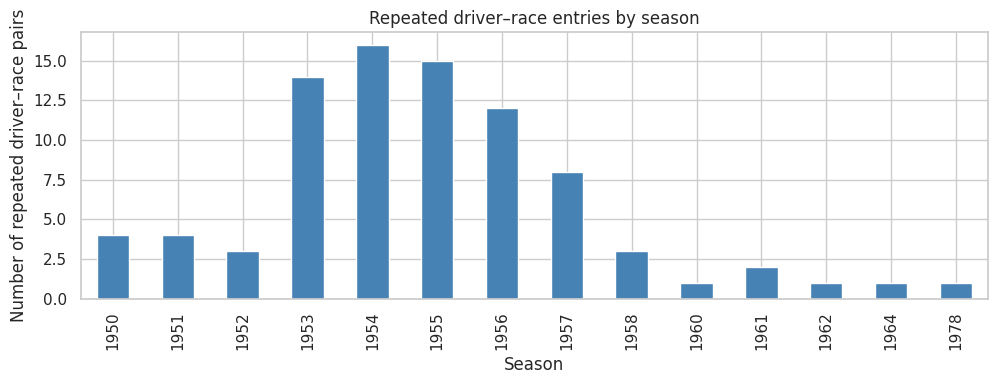

In [8]:
# Add race information to the repeated driver–race records.
# many_to_one verifies that each raceId matches only one race.
duplicate_details = duplicate_driver_races.merge(
    clean_tables["races"][["raceId", "year", "name"]],
    on="raceId",
    how="left",
    validate="many_to_one"
).rename(columns={"name": "race_name"})

# Add driver names so the records are easier to understand.
duplicate_details = duplicate_details.merge(
    clean_tables["drivers"][["driverId", "forename", "surname"]],
    on="driverId",
    how="left",
    validate="many_to_one"
)

# Count repeated driver–race pairs in each season.
# Count each pair once, even if it contains several result records.
duplicate_pairs_by_year = (
    duplicate_details[["year", "raceId", "driverId"]]
    .drop_duplicates()
    .groupby("year")
    .size()
    .rename("Repeated driver–race pairs")
)

display(duplicate_pairs_by_year.to_frame())

# Show the actual records with their historical context.
display(
    duplicate_details[
        ["year", "race_name", "forename", "surname",
         "resultId", "constructorId", "grid", "positionOrder"]
    ]
    .sort_values(["year", "race_name", "surname", "resultId"])
    .head(20)
)

# Visualize which seasons contain repeated entries.
if not duplicate_pairs_by_year.empty:
    duplicate_pairs_by_year.plot(
        kind="bar",
        figsize=(10, 4),
        color="steelblue"
    )

    plt.xlabel("Season")
    plt.ylabel("Number of repeated driver–race pairs")
    plt.title("Repeated driver–race entries by season")
    plt.tight_layout()
    plt.show()

In [9]:
# Work on a separate inspection table.
duplicate_review = duplicate_details.copy()

# Convert grid values to numbers for this check.
duplicate_review["grid_numeric"] = pd.to_numeric(
    duplicate_review["grid"],
    errors="raise"
)

# A positive grid gives a recorded starting position.
# This alone does not prove which car the driver originally started in.
duplicate_review["positive_grid"] = (
    duplicate_review["grid_numeric"] > 0
)

# Count how many rows in each repeated pair have a positive grid.
duplicate_grid_check = (
    duplicate_review
    .groupby(["raceId", "driverId"])
    .agg(
        year=("year", "first"),
        records=("resultId", "size"),
        positive_grid_rows=("positive_grid", "sum")
    )
    .reset_index()
)

# Summarize whether a "keep the positive grid" rule is unambiguous.
print("Repeated pairs grouped by number of positive-grid rows:")
display(
    duplicate_grid_check
    .groupby("positive_grid_rows")
    .size()
    .rename("Number of driver–race pairs")
    .to_frame()
)

# Inspect the later repeated entries separately.
# Add the recorded status to help understand these cases.
later_duplicates = duplicate_review.loc[
    duplicate_review["year"] > 1957
].merge(
    clean_tables["status"][["statusId", "status"]],
    on="statusId",
    how="left",
    validate="many_to_one"
)

display(
    later_duplicates[
        ["year", "race_name", "forename", "surname",
         "resultId", "constructorId", "grid",
         "positionOrder", "status"]
    ].sort_values(
        ["year", "race_name", "surname", "resultId"]
    )
)

Repeated pairs grouped by number of positive-grid rows:


,Number of driver–race pairs
positive_grid_rows,
0,3
2,76
3,6


,year,race_name,forename,surname,resultId,constructorId,grid,positionOrder,status
14,1958,French Grand Prix,Tony,Brooks,18612,118,5,18,Engine
15,1958,French Grand Prix,Tony,Brooks,20296,118,10,14,Engine
16,1958,Italian Grand Prix,Carroll,Shelby,18694,105,17,18,Handling
17,1958,Italian Grand Prix,Carroll,Shelby,20297,105,11,4,+1 Lap
12,1958,Monaco Grand Prix,Ron,Flockhart,18510,87,0,17,Did not qualify
13,1958,Monaco Grand Prix,Ron,Flockhart,18520,66,0,27,Did not qualify
10,1960,Argentine Grand Prix,Stirling,Moss,18083,170,1,17,Suspension
11,1960,Argentine Grand Prix,Stirling,Moss,22372,170,8,3,Finished
6,1961,British Grand Prix,Stirling,Moss,17962,102,20,19,Disqualified
7,1961,British Grand Prix,Stirling,Moss,17964,172,5,21,Brakes


### 1.7 Create one row per driver and race

For historical summaries, retain the best recorded finish, breaking ties with the smallest result ID. Flag all 85 ambiguous pairs for exclusion from modeling: choosing pre-race features using the eventual finish could bias predictions. This removes 91 extra rows from the separate driver–race table; the full results table is retained.


In [10]:
# Create a separate driver–race table.
# Keep clean_tables["results"] unchanged for reference and other analyses.
results_for_selection = clean_tables["results"].copy()

# Ensure finishing positions are sorted numerically.
results_for_selection["positionOrder"] = pd.to_numeric(
    results_for_selection["positionOrder"],
    errors="raise"
)

assert results_for_selection["positionOrder"].notna().all(), (
    "Missing finishing ranks need investigation before selecting records."
)

# Flag every record belonging to a repeated driver–race pair.
results_for_selection["ambiguous_driver_race"] = (
    results_for_selection.duplicated(
        subset=["raceId", "driverId"],
        keep=False
    )
)

# Keep the best recorded finish for each driver–race pair.
# resultId provides a consistent tie-breaker.
results_driver_race = (
    results_for_selection
    .sort_values(["raceId", "driverId", "positionOrder", "resultId"])
    .drop_duplicates(subset=["raceId", "driverId"], keep="first")
    .reset_index(drop=True)
)

# Verify that every driver–race pair is now unique.
assert not results_driver_race.duplicated(
    subset=["raceId", "driverId"]
).any(), "Repeated driver–race pairs remain."

# Record the effect of this cleaning decision.
duplicate_handling_summary = pd.DataFrame({
    "Measure": [
        "Original result rows",
        "Unique driver–race rows",
        "Extra records removed from this table",
        "Ambiguous pairs flagged",
        "Unambiguous rows available before further checks"
    ],
    "Count": [
        len(results_for_selection),
        len(results_driver_race),
        len(results_for_selection) - len(results_driver_race),
        int(results_driver_race["ambiguous_driver_race"].sum()),
        int((~results_driver_race["ambiguous_driver_race"]).sum())
    ]
})

display(duplicate_handling_summary)

,Measure,Count
0,Original result rows,26759
1,Unique driver–race rows,26668
2,Extra records removed from this table,91
3,Ambiguous pairs flagged,85
4,Unambiguous rows available before further checks,26583


### 1.8 Check that references match existing records

Before joining tables, check that each referenced driver, race, constructor, circuit, status, and season exists in its parent table. Missing or unmatched references could cause incomplete joins. All checked references matched.


In [11]:
# Define where each reference column should point.
# Example: driverId should reference drivers.driverId.
reference_tables = {
    "raceId": ("races", "raceId"),
    "driverId": ("drivers", "driverId"),
    "constructorId": ("constructors", "constructorId"),
    "circuitId": ("circuits", "circuitId"),
    "statusId": ("status", "statusId")
}

foreign_key_records = []

for table_name, table in clean_tables.items():
    for column, (parent_name, parent_key) in reference_tables.items():

        # Check tables containing this reference column.
        # Skip the parent table itself.
        if column in table.columns and table_name != parent_name:

            # Get the valid IDs from the referenced table.
            valid_ids = clean_tables[parent_name][parent_key]

            # Separate missing references from IDs that do not exist.
            missing_mask = table[column].isna()

            unmatched_mask = (
                table[column].notna()
                & ~table[column].isin(valid_ids)
            )

            foreign_key_records.append({
                "Table": table_name,
                "Reference": column,
                "Parent table": parent_name,
                "Missing references": int(missing_mask.sum()),
                "Unmatched references": int(unmatched_mask.sum())
            })

# Check that each race's year also exists in the seasons table.
foreign_key_records.append({
    "Table": "races",
    "Reference": "year",
    "Parent table": "seasons",
    "Missing references": int(clean_tables["races"]["year"].isna().sum()),
    "Unmatched references": int(
        (
            clean_tables["races"]["year"].notna()
            & ~clean_tables["races"]["year"].isin(
                clean_tables["seasons"]["year"]
            )
        ).sum()
    )
})

foreign_key_audit = pd.DataFrame(foreign_key_records)
display(foreign_key_audit)

# Summarize the findings without changing any data.
print(
    "Total missing references:",
    foreign_key_audit["Missing references"].sum()
)

print(
    "Total unmatched references:",
    foreign_key_audit["Unmatched references"].sum()
)

,Table,Reference,Parent table,Missing references,Unmatched references
0,constructor_results,raceId,races,0,0
1,constructor_results,constructorId,constructors,0,0
2,constructor_standings,raceId,races,0,0
3,constructor_standings,constructorId,constructors,0,0
4,driver_standings,raceId,races,0,0
5,driver_standings,driverId,drivers,0,0
6,lap_times,raceId,races,0,0
7,lap_times,driverId,drivers,0,0
8,pit_stops,raceId,races,0,0
9,pit_stops,driverId,drivers,0,0


Total missing references: 0
Total unmatched references: 0


### 1.9 Convert date text into dates

Convert race, session, and birth dates so we can sort events and calculate time differences. Check that no existing date fails conversion. Dates already missing remain missing.


In [12]:
# Race dates, session dates, and driver birth dates should be dates,
# rather than ordinary text.
date_columns = {
    "races": [
        "date", "fp1_date", "fp2_date",
        "fp3_date", "quali_date", "sprint_date"
    ],
    "drivers": ["dob"]
}

date_conversion_records = []

for table_name, columns in date_columns.items():
    for column in columns:

        original = clean_tables[table_name][column].copy()

        # Read dates in year-month-day format.
        # Unreadable values become NaT (pandas' missing-date value).
        converted = pd.to_datetime(
            original,
            format="%Y-%m-%d",
            errors="coerce"
        )

        # Detect values that were present but could not be parsed.
        failed_mask = original.notna() & converted.isna()

        date_conversion_records.append({
            "Table": table_name,
            "Column": column,
            "Missing before": int(original.isna().sum()),
            "Missing after": int(converted.isna().sum()),
            "Conversion failures": int(failed_mask.sum())
        })

        # Stop if conversion would silently lose a recorded value.
        if failed_mask.any():
            print(f"Unrecognized dates in {table_name}.{column}:")
            display(original.loc[failed_mask].head(10))
            raise ValueError("Review these dates before continuing.")

        # Update only the working table.
        clean_tables[table_name][column] = converted

date_conversion_audit = pd.DataFrame(date_conversion_records)
display(date_conversion_audit)

# Show a few converted race dates.
display(clean_tables["races"][["raceId", "year", "date"]].head())

print("Race date type:", clean_tables["races"]["date"].dtype)
print("Driver birth-date type:", clean_tables["drivers"]["dob"].dtype)

,Table,Column,Missing before,Missing after,Conversion failures
0,races,date,0,0,0
1,races,fp1_date,1035,1035,0
2,races,fp2_date,1035,1035,0
3,races,fp3_date,1053,1053,0
4,races,quali_date,1035,1035,0
5,races,sprint_date,1107,1107,0
6,drivers,dob,0,0,0


,raceId,year,date
0,1,2009,2009-03-29
1,2,2009,2009-04-05
2,3,2009,2009-04-19
3,4,2009,2009-04-26
4,5,2009,2009-05-10


Race date type: datetime64[ns]
Driver birth-date type: datetime64[ns]


### 1.10 Convert qualifying times into seconds

Text such as `1:26.572` becomes `86.572` seconds so we can compare and calculate with it. Preserve the original text and missing values, and check for invalid times. Missing Q2 or Q3 times are not automatically errors.


In [13]:
# Convert a qualifying time from "minutes:seconds" to total seconds.
def qualifying_time_to_seconds(value):

    # Keep missing times missing.
    if pd.isna(value):
        return np.nan

    parts = str(value).strip().split(":")

    # Expect two parts, such as "1" and "23.456".
    if len(parts) != 2:
        raise ValueError(f"Unexpected qualifying time: {value}")

    minutes = int(parts[0])
    seconds = float(parts[1])

    # Reject invalid time components instead of silently accepting them.
    if minutes < 0 or not np.isfinite(seconds) or not 0 <= seconds < 60:
        raise ValueError(f"Invalid qualifying time: {value}")

    return minutes * 60 + seconds


qualifying = clean_tables["qualifying"]
time_conversion_records = []

for column in ["q1", "q2", "q3"]:

    # Create a numeric column while preserving the original time text.
    seconds_column = column + "_seconds"

    qualifying[seconds_column] = qualifying[column].apply(
        qualifying_time_to_seconds
    )

    # Verify that conversion did not introduce additional missing values.
    assert qualifying[column].isna().equals(
        qualifying[seconds_column].isna()
    ), f"Missing values changed during conversion of {column}."

    time_conversion_records.append({
        "Original column": column,
        "New column": seconds_column,
        "Missing before": int(qualifying[column].isna().sum()),
        "Missing after": int(qualifying[seconds_column].isna().sum()),
        "Non-positive times": int(
            (qualifying[seconds_column] <= 0).sum()
        )
    })

display(pd.DataFrame(time_conversion_records))

# Compare the original text with the converted numbers.
display(
    qualifying[
        ["q1", "q1_seconds", "q2", "q2_seconds", "q3", "q3_seconds"]
    ].head(10)
)

,Original column,New column,Missing before,Missing after,Non-positive times
0,q1,q1_seconds,156,156,0
1,q2,q2_seconds,4647,4647,0
2,q3,q3_seconds,6865,6865,0


,q1,q1_seconds,q2,q2_seconds,q3,q3_seconds
0,1:26.572,86.572,1:25.187,85.187,1:26.714,86.714
1,1:26.103,86.103,1:25.315,85.315,1:26.869,86.869
2,1:25.664,85.664,1:25.452,85.452,1:27.079,87.079
3,1:25.994,85.994,1:25.691,85.691,1:27.178,87.178
4,1:25.960,85.960,1:25.518,85.518,1:27.236,87.236
5,1:26.427,86.427,1:26.101,86.101,1:28.527,88.527
6,1:26.295,86.295,1:26.059,86.059,1:28.687,88.687
7,1:26.381,86.381,1:26.063,86.063,1:29.041,89.041
8,1:26.919,86.919,1:26.164,86.164,1:29.593,89.593
9,1:26.702,86.702,1:25.842,85.842,NaN,NaN


### 1.11 Check qualifying coverage by season

A result row does not always have a matching qualifying record or Q1 time. Measure both separately. Coverage is inconsistent before 2003 and nearly complete afterward, supporting 2003–2024 as a candidate modeling period while retaining older data for analysis.


First season with matching qualifying records: 1994


,year,driver_race_rows,qualifying_record_percent,q1_time_percent
40,1990,542,0.00,0.00
41,1991,539,0.00,0.00
42,1992,478,0.00,0.00
43,1993,412,0.00,0.00
44,1994,444,88.29,88.06
45,1995,418,100.00,94.26
46,1996,340,43.53,42.65
47,1997,376,58.51,58.24
48,1998,349,43.84,43.27
49,1999,352,18.47,18.18


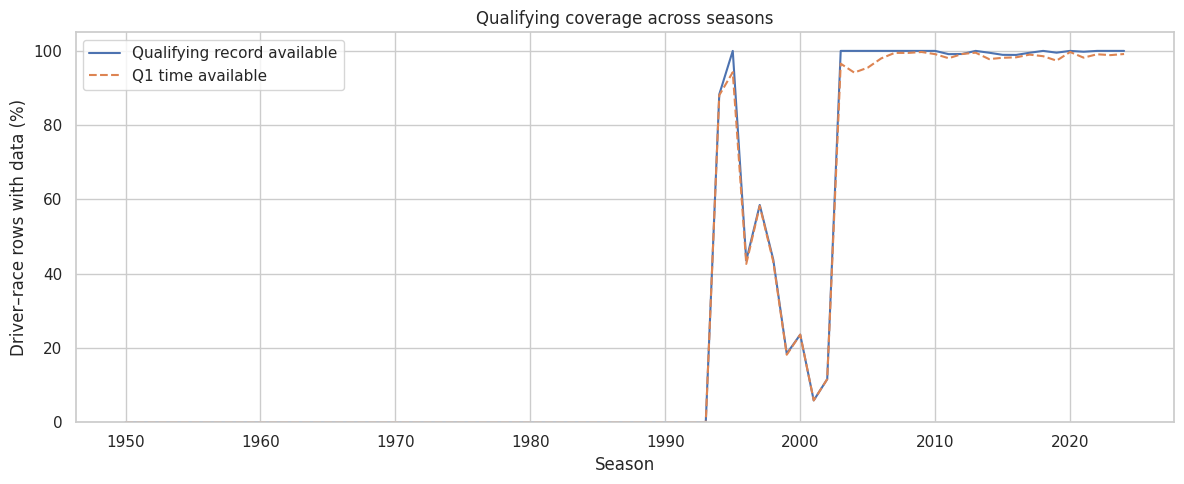

In [14]:
# Verify that qualifying has at most one record per driver per race.
# Unique qualifyId values alone do not guarantee this.
assert not clean_tables["qualifying"].duplicated(
    ["raceId", "driverId"]
).any(), "Repeated qualifying entries need investigation."

# Start with one row per driver–race to avoid counting duplicates twice.
qualifying_coverage_rows = results_driver_race[
    ["raceId", "driverId"]
].merge(
    clean_tables["races"][["raceId", "year"]],
    on="raceId",
    how="left",
    validate="many_to_one"
)

# Keep every driver–race row, even when qualifying is unavailable.
qualifying_coverage_rows = qualifying_coverage_rows.merge(
    clean_tables["qualifying"][
        ["raceId", "driverId", "qualifyId", "q1_seconds"]
    ],
    on=["raceId", "driverId"],
    how="left",
    validate="one_to_one"
)

# Record whether a qualifying row and a Q1 time are available.
qualifying_coverage_rows["has_qualifying_record"] = (
    qualifying_coverage_rows["qualifyId"].notna()
)

qualifying_coverage_rows["has_q1_time"] = (
    qualifying_coverage_rows["q1_seconds"].notna()
)

# A mean of True/False values gives the proportion that are True.
qualifying_coverage = (
    qualifying_coverage_rows
    .groupby("year")
    .agg(
        driver_race_rows=("driverId", "size"),
        qualifying_record_percent=("has_qualifying_record", "mean"),
        q1_time_percent=("has_q1_time", "mean")
    )
    .reset_index()
)

percentage_columns = [
    "qualifying_record_percent",
    "q1_time_percent"
]

qualifying_coverage[percentage_columns] *= 100

# Identify the first season with matching qualifying records.
covered_years = qualifying_coverage.loc[
    qualifying_coverage["qualifying_record_percent"] > 0,
    "year"
]

print(
    "First season with matching qualifying records:",
    covered_years.min()
)

# Display recent decades and plot the full historical coverage.
display(
    qualifying_coverage.loc[
        qualifying_coverage["year"] >= 1990
    ].round(2)
)

plt.figure(figsize=(12, 5))

plt.plot(
    qualifying_coverage["year"],
    qualifying_coverage["qualifying_record_percent"],
    label="Qualifying record available"
)

plt.plot(
    qualifying_coverage["year"],
    qualifying_coverage["q1_time_percent"],
    label="Q1 time available",
    linestyle="--"
)

plt.xlabel("Season")
plt.ylabel("Driver–race rows with data (%)")
plt.title("Qualifying coverage across seasons")
plt.ylim(0, 105)
plt.legend()
plt.tight_layout()
plt.show()

### 1.12 Investigate and handle zero grid positions

Zero is a special grid code, not a position ahead of first place. Its associated statuses vary, so we do not assume it always means the same thing. Preserve `grid`, add `grid_is_zero`, and leave `grid_position` missing for zeros. Status is used here for inspection, not as a current-race prediction input.


In [15]:
# Build a separate inspection table using the unique driver–race rows.
grid_status_review = results_driver_race.merge(
    clean_tables["races"][["raceId", "year"]],
    on="raceId",
    how="left",
    validate="many_to_one"
).merge(
    clean_tables["status"][["statusId", "status"]],
    on="statusId",
    how="left",
    validate="many_to_one"
)

# Ensure grid positions are numeric.
grid_status_review["grid"] = pd.to_numeric(
    grid_status_review["grid"],
    errors="raise"
)

# Compare the full historical data with the candidate modeling period.
grid_check_records = []

for label, subset in [
    ("All seasons", grid_status_review),
    ("2003 onward", grid_status_review.loc[
        grid_status_review["year"] >= 2003
    ])
]:
    grid_check_records.append({
        "Period": label,
        "Rows": len(subset),
        "Missing grid": int(subset["grid"].isna().sum()),
        "Grid equals zero": int(subset["grid"].eq(0).sum()),
        "Negative grid": int(subset["grid"].lt(0).sum())
    })

display(pd.DataFrame(grid_check_records))

# Examine the recorded outcomes of modern entries with grid zero.
# Status is used for this audit, not as a prediction feature.
modern_zero_grid = grid_status_review.loc[
    (grid_status_review["year"] >= 2003)
    & grid_status_review["grid"].eq(0)
]

display(
    modern_zero_grid["status"]
    .value_counts(dropna=False)
    .rename_axis("Status")
    .reset_index(name="Driver–race entries with grid zero")
)

,Period,Rows,Missing grid,Grid equals zero,Negative grid
0,All seasons,26668,0,1635,0
1,2003 onward,8970,0,86,0


,Status,Driver–race entries with grid zero
0,+1 Lap,27
1,Finished,22
2,+2 Laps,7
3,Withdrew,5
4,Did not qualify,4
5,Collision damage,3
6,Brakes,2
7,Retired,2
8,Power Unit,2
9,Accident,2


In [16]:
# Keep the original grid and ensure it is numeric.
results_driver_race["grid"] = pd.to_numeric(
    results_driver_race["grid"],
    errors="raise"
)

# Flag the special zero code without claiming it always means pit-lane start.
results_driver_race["grid_is_zero"] = (
    results_driver_race["grid"].eq(0).astype(int)
)

# Only positive grid values represent an ordinary numbered grid position.
# Keep zero-coded positions missing in this new column.
results_driver_race["grid_position"] = (
    results_driver_race["grid"].where(
        results_driver_race["grid"] > 0
    )
)

# Verify that ordinary grid positions stayed unchanged.
positive_grid = results_driver_race["grid"] > 0

assert (
    results_driver_race.loc[positive_grid, "grid_position"]
    == results_driver_race.loc[positive_grid, "grid"]
).all()

assert results_driver_race.loc[
    results_driver_race["grid_is_zero"] == 1,
    "grid_position"
].isna().all()

# Summarize the transformation across all seasons.
display(pd.DataFrame({
    "Measure": [
        "Driver–race rows retained",
        "Zero-grid entries flagged",
        "Missing values in grid_position"
    ],
    "Count": [
        len(results_driver_race),
        int(results_driver_race["grid_is_zero"].sum()),
        int(results_driver_race["grid_position"].isna().sum())
    ]
}))

# Show examples of both ordinary and zero-coded grids.
display(
    results_driver_race.loc[
        results_driver_race["grid_is_zero"] == 0,
        ["raceId", "driverId", "grid", "grid_is_zero", "grid_position"]
    ].head(3)
)

display(
    results_driver_race.loc[
        results_driver_race["grid_is_zero"] == 1,
        ["raceId", "driverId", "grid", "grid_is_zero", "grid_position"]
    ].head(3)
)

,Measure,Count
0,Driver–race rows retained,26668
1,Zero-grid entries flagged,1635
2,Missing values in grid_position,1635


,raceId,driverId,grid,grid_is_zero,grid_position
0,1,1,18,0,18.0
1,1,2,9,0,9.0
2,1,3,5,0,5.0


,raceId,driverId,grid,grid_is_zero,grid_position
190,10,13,0,1,NaN
2619,127,62,0,1,NaN
2761,134,21,0,1,NaN


### 1.13 Create the podium target and check its balance

Validate finishing ranks, then label the top three as `podium = 1` and all others as `0`. In the candidate period, 14.31% of entries are podiums, so accuracy alone can be misleading. Finishing rank defines the target and must not be an input feature.


,Outcome,Rows,Percent
0,No podium,7686,85.69
1,Podium,1284,14.31


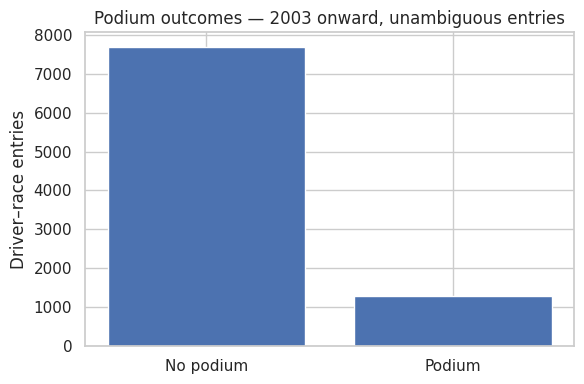

In [17]:
# Validate finishing positions before creating the target.
position = pd.to_numeric(
    results_driver_race["positionOrder"], errors="raise"
)

assert position.notna().all(), "Some finishing positions are missing."
assert (position >= 1).all(), "Some finishing positions are below 1."
assert (position % 1 == 0).all(), "Some finishing positions are not whole numbers."

results_driver_race["positionOrder"] = position.astype(int)

# Top three finishing positions count as a podium.
results_driver_race["podium"] = (
    results_driver_race["positionOrder"] <= 3
).astype(int)

# Inspect the candidate modeling period without changing the full table.
podium_review = results_driver_race.merge(
    clean_tables["races"][["raceId", "year"]],
    on="raceId",
    how="left",
    validate="many_to_one"
)

podium_review = podium_review.loc[
    (podium_review["year"] >= 2003)
    & (~podium_review["ambiguous_driver_race"])
].copy()

counts = (
    podium_review["podium"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

target_summary = pd.DataFrame({
    "Outcome": ["No podium", "Podium"],
    "Rows": counts.to_numpy(),
    "Percent": (counts / counts.sum() * 100).round(2).to_numpy()
})

display(target_summary)

plt.figure(figsize=(6, 4))
plt.bar(target_summary["Outcome"], target_summary["Rows"])
plt.title("Podium outcomes — 2003 onward, unambiguous entries")
plt.ylabel("Driver–race entries")
plt.tight_layout()
plt.show()

### 1.14 Make sure numerical columns contain numbers

Some numerical columns remain stored as text after missing markers are replaced. Convert them and check for unexpected text, infinite values, and changed missing counts. Update the separate driver–race table too; no rows are removed.


In [18]:
# Columns that should contain numerical measurements or positions.
numeric_columns = {
    "results": [
        "grid", "position", "positionOrder", "points", "laps",
        "milliseconds", "fastestLap", "rank", "fastestLapSpeed"
    ],
    "qualifying": ["position"],
    "driver_standings": ["points", "position", "wins"],
    "constructor_standings": ["points", "position", "wins"],
    "constructor_results": ["points"],
    "lap_times": ["lap", "position", "milliseconds"],
    "pit_stops": ["stop", "lap", "milliseconds"],
    "sprint_results": [
        "grid", "position", "positionOrder", "points",
        "laps", "milliseconds", "fastestLap"
    ],
    "circuits": ["lat", "lng", "alt"]
}

numeric_checks = []

def convert_numeric_columns(table, table_name, columns):
    for column in columns:
        original = table[column]
        converted = pd.to_numeric(original, errors="coerce")

        # Detect actual conversion problems, not existing missing values.
        failures = original.notna() & converted.isna()

        if failures.any():
            examples = original.loc[failures].head().tolist()
            raise ValueError(
                f"{table_name}.{column}: unexpected values {examples}"
            )

        assert np.isfinite(converted.dropna()).all(), (
            f"{table_name}.{column} contains infinite values."
        )

        numeric_checks.append({
            "Table": table_name,
            "Column": column,
            "Type before": str(original.dtype),
            "Type after": str(converted.dtype),
            "Missing before": int(original.isna().sum()),
            "Missing after": int(converted.isna().sum())
        })

        table[column] = converted


for table_name, columns in numeric_columns.items():
    convert_numeric_columns(
        clean_tables[table_name], table_name, columns
    )

# This is a separate table, so update its numerical columns too.
convert_numeric_columns(
    results_driver_race,
    "results_driver_race",
    numeric_columns["results"]
)

numeric_audit = pd.DataFrame(numeric_checks)

assert (
    numeric_audit["Missing before"] == numeric_audit["Missing after"]
).all(), "The conversion unexpectedly changed missing-value counts."

display(numeric_audit)

print("Numerical checks passed. Existing missing values were preserved.")
print("No rows were removed by this cell.")

,Table,Column,Type before,Type after,Missing before,Missing after
0,results,grid,int64,int64,0,0
1,results,position,object,float64,10953,10953
2,results,positionOrder,int64,int64,0,0
3,results,points,float64,float64,0,0
4,results,laps,int64,int64,0,0
5,results,milliseconds,object,float64,19079,19079
6,results,fastestLap,object,float64,18507,18507
7,results,rank,object,float64,18249,18249
8,results,fastestLapSpeed,object,float64,18507,18507
9,qualifying,position,int64,int64,0,0


Numerical checks passed. Existing missing values were preserved.
No rows were removed by this cell.


## 2. Data Analysis and Feature Engineering

### 2.1 Front-Row Starts and Podium Conversion

We examine how often drivers starting in grid positions 1 or 2 finish on the podium at each circuit. We then compare the results before and after 2014.

In [19]:
# Combine results with race and circuit information.
front_row_data = results_driver_race.merge(
    clean_tables["races"][["raceId", "year", "circuitId"]],
    on="raceId",
    how="left",
    validate="many_to_one"
)

front_row_data = front_row_data.merge(
    clean_tables["circuits"][["circuitId", "name"]],
    on="circuitId",
    how="left",
    validate="many_to_one"
)

# Select drivers starting from grid positions 1 or 2.
front_row_data = front_row_data[
    front_row_data["grid"].isin([1, 2])
].copy()

print("Total front-row starts:", len(front_row_data))

display(
    front_row_data[
        ["year", "name", "grid", "positionOrder", "podium"]
    ].head(10)
)

Total front-row starts: 2243


,year,name,grid,positionOrder,podium
15,2009,Albert Park Grand Prix Circuit,1,1,1
18,2009,Albert Park Grand Prix Circuit,2,2,1
32,2009,Sepang International Circuit,2,4,0
35,2009,Sepang International Circuit,1,1,1
43,2009,Shanghai International Circuit,2,9,0
56,2009,Shanghai International Circuit,1,1,1
69,2009,Bahrain International Circuit,2,7,0
72,2009,Bahrain International Circuit,1,3,1
95,2009,Circuit de Barcelona-Catalunya,1,1,1
96,2009,Circuit de Barcelona-Catalunya,2,4,0


In [20]:
# Calculate podium conversion rates for each circuit.
circuit_podium_rates = (
    front_row_data
    .groupby("name")
    .agg(
        front_row_starts=("podium", "size"),
        podium_finishes=("podium", "sum")
    )
    .reset_index()
)

# Calculate the percentage of front-row starts ending in a podium.
circuit_podium_rates["podium_rate"] = (
    circuit_podium_rates["podium_finishes"]
    / circuit_podium_rates["front_row_starts"] * 100
)

# Rank circuits from highest to lowest conversion rate.
circuit_podium_rates = circuit_podium_rates.sort_values(
    ["podium_rate", "front_row_starts"],
    ascending=[False, False]
)

display(circuit_podium_rates.head(15))

,name,front_row_starts,podium_finishes,podium_rate
51,Miami International Autodrome,6,6,100.000000
10,Autódromo Internacional do Algarve,4,4,100.000000
46,Las Vegas Strip Street Circuit,4,4,100.000000
2,Ain Diab,2,2,100.000000
6,Autodromo Internazionale del Mugello,2,2,100.000000
34,Donington Park,2,2,100.000000
58,Pescara Circuit,2,2,100.000000
42,Jeddah Corniche Circuit,8,7,87.500000
29,Circuit of the Americas,24,20,83.333333
17,Buddh International Circuit,6,5,83.333333


In [21]:
# Separate races into the two periods.
front_row_data["era"] = np.where(
    front_row_data["year"] < 2014,
    "Before 2014",
    "2014 Onward"
)

# Calculate podium conversion rates for each circuit and era.
era_podium_rates = (
    front_row_data
    .groupby(["name", "era"])
    .agg(
        front_row_starts=("podium", "size"),
        podium_finishes=("podium", "sum")
    )
    .reset_index()
)

era_podium_rates["podium_rate"] = (
    era_podium_rates["podium_finishes"]
    / era_podium_rates["front_row_starts"] * 100
)

# Display the top 10 circuits in each era.
for era in ["Before 2014", "2014 Onward"]:
    print(f"\nTop 10 circuits — {era}")

    display(
        era_podium_rates[
            era_podium_rates["era"] == era
        ]
        .sort_values(
            ["podium_rate", "front_row_starts"],
            ascending=[False, False]
        )
        .head(10)
    )


Top 10 circuits — Before 2014


,name,era,front_row_starts,podium_finishes,podium_rate
42,Circuit of the Americas,Before 2014,4,4,100.000000
2,Ain Diab,Before 2014,2,2,100.000000
47,Donington Park,Before 2014,2,2,100.000000
76,Pescara Circuit,Before 2014,2,2,100.000000
23,Buddh International Circuit,Before 2014,6,5,83.333333
37,Circuit de Nevers Magny-Cours,Before 2014,36,29,80.555556
56,Istanbul Park,Before 2014,14,11,78.571429
3,Aintree,Before 2014,9,7,77.777778
46,Dijon-Prenois,Before 2014,12,9,75.000000
75,Okayama International Circuit,Before 2014,4,3,75.000000



Top 10 circuits — 2014 Onward


,name,era,front_row_starts,podium_finishes,podium_rate
68,Miami International Autodrome,2014 Onward,6,6,100.000000
14,Autódromo Internacional do Algarve,2014 Onward,4,4,100.000000
62,Las Vegas Strip Street Circuit,2014 Onward,4,4,100.000000
8,Autodromo Internazionale del Mugello,2014 Onward,2,2,100.000000
93,Suzuka Circuit,2014 Onward,18,16,88.888889
29,Circuit Park Zandvoort,2014 Onward,8,7,87.500000
58,Jeddah Corniche Circuit,2014 Onward,8,7,87.500000
97,Yas Marina Circuit,2014 Onward,22,19,86.363636
86,Sepang International Circuit,2014 Onward,7,6,85.714286
35,Circuit de Monaco,2014 Onward,20,17,85.000000


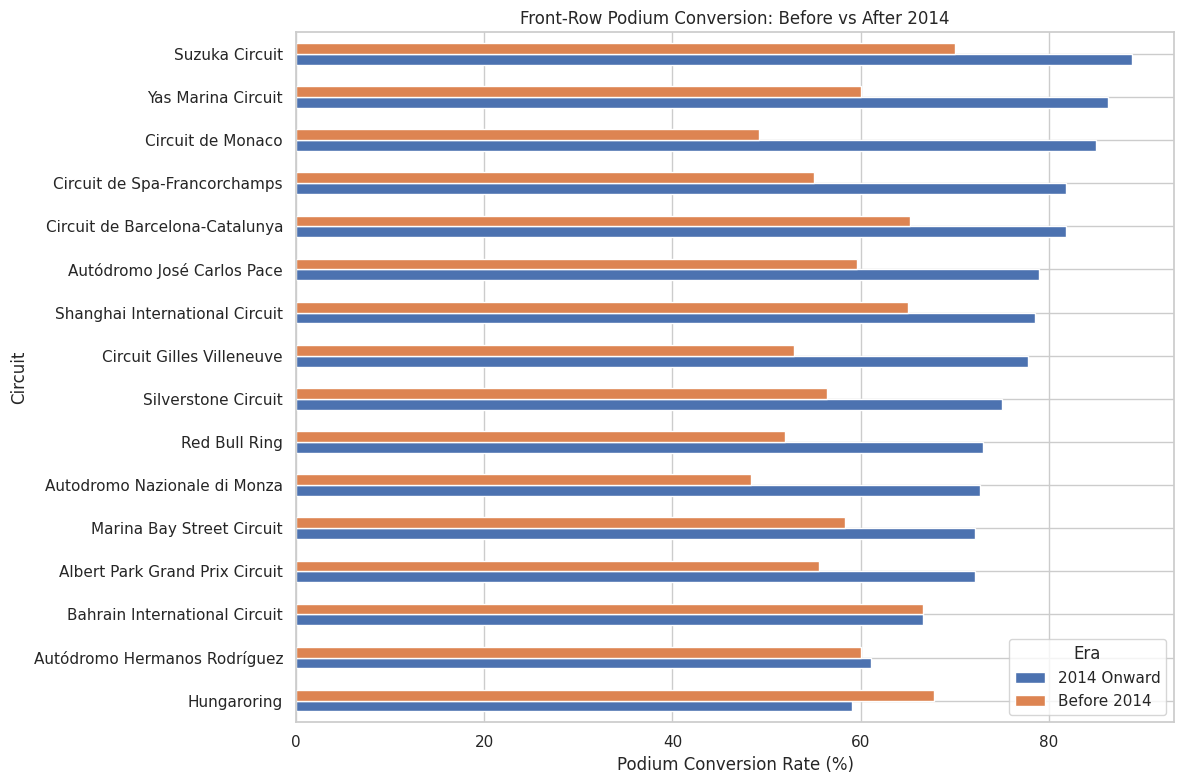

In [22]:
# Compare circuits with enough front-row starts in both eras.
era_comparison = era_podium_rates.pivot(
    index="name",
    columns="era",
    values=["podium_rate", "front_row_starts"]
)

# Keep circuits with at least 10 starts in each era.
eligible = (
    (era_comparison["front_row_starts"]["Before 2014"] >= 10)
    & (era_comparison["front_row_starts"]["2014 Onward"] >= 10)
)

era_comparison = era_comparison.loc[eligible]

# Plot the podium conversion rates.
era_comparison["podium_rate"].sort_values(
    "2014 Onward"
).plot(
    kind="barh",
    figsize=(12, 8)
)

plt.xlabel("Podium Conversion Rate (%)")
plt.ylabel("Circuit")
plt.title("Front-Row Podium Conversion: Before vs After 2014")
plt.legend(title="Era")
plt.tight_layout()
plt.show()#

In [23]:
# Get the conversion rates for both eras.
ranking_comparison = era_comparison["podium_rate"].copy()

# Rank circuits within each era.
ranking_comparison["Rank Before 2014"] = (
    ranking_comparison["Before 2014"]
    .rank(ascending=False, method="min")
    .astype(int)
)

ranking_comparison["Rank 2014 Onward"] = (
    ranking_comparison["2014 Onward"]
    .rank(ascending=False, method="min")
    .astype(int)
)

# Positive values mean the circuit moved up in the ranking.
ranking_comparison["Rank Change"] = (
    ranking_comparison["Rank Before 2014"]
    - ranking_comparison["Rank 2014 Onward"]
)

# Calculate the percentage-point difference.
ranking_comparison["Rate Change"] = (
    ranking_comparison["2014 Onward"]
    - ranking_comparison["Before 2014"]
)

# Display the comparison.
display(
    ranking_comparison.sort_values(
        "Rank 2014 Onward"
    ).round(2)
)

era,2014 Onward,Before 2014,Rank Before 2014,Rank 2014 Onward,Rank Change,Rate Change
name,,,,,,
Suzuka Circuit,88.89,70.00,1,1,0,18.89
Yas Marina Circuit,86.36,60.00,6,2,4,26.36
Circuit de Monaco,85.00,49.17,15,3,12,35.83
Circuit de Barcelona-Catalunya,81.82,65.22,4,4,0,16.60
Circuit de Spa-Francorchamps,81.82,55.06,12,4,8,26.76
Autódromo José Carlos Pace,78.95,59.68,8,6,2,19.27
Shanghai International Circuit,78.57,65.00,5,7,-2,13.57
Circuit Gilles Villeneuve,77.78,52.94,13,8,5,24.84
Silverstone Circuit,75.00,56.38,10,9,1,18.62


### 2.1.1 Findings

The results show that circuit rankings changed after 2014. Suzuka remained the highest-ranked circuit, with its podium conversion rate increasing from 70% to 88.89%.

Monaco showed a major improvement, moving from 15th to 3rd place, while Hungaroring dropped from 2nd to 16th.

Overall, most circuits had higher podium conversion rates after 2014. However, these results show an association rather than proving that the regulation changes caused the differences. We also limited the ranking comparison to circuits with at least 10 front-row starts in each period to reduce the effect of small samples.

### 2.2 Home-Country Advantage

We investigate whether drivers are more likely to finish on the podium when racing in their home country. We will also account for starting grid position to make the comparison fairer.

In [24]:
# Inspect driver nationalities.
print("Driver nationalities:")
print(sorted(clean_tables["drivers"]["nationality"].dropna().unique()))

# Inspect circuit countries.
print("\nCircuit countries:")
print(sorted(clean_tables["circuits"]["country"].dropna().unique()))

Driver nationalities:
['American', 'American-Italian', 'Argentine', 'Argentine-Italian', 'Argentinian ', 'Australian', 'Austrian', 'Belgian', 'Brazilian', 'British', 'Canadian', 'Chilean', 'Chinese', 'Colombian', 'Czech', 'Danish', 'Dutch', 'East German', 'Finnish', 'French', 'German', 'Hungarian', 'Indian', 'Indonesian', 'Irish', 'Italian', 'Japanese', 'Liechtensteiner', 'Malaysian', 'Mexican', 'Monegasque', 'New Zealander', 'Polish', 'Portuguese', 'Rhodesian', 'Russian', 'South African', 'Spanish', 'Swedish', 'Swiss', 'Thai', 'Uruguayan', 'Venezuelan']

Circuit countries:
['Argentina', 'Australia', 'Austria', 'Azerbaijan', 'Bahrain', 'Belgium', 'Brazil', 'Canada', 'China', 'France', 'Germany', 'Hungary', 'India', 'Italy', 'Japan', 'Korea', 'Malaysia', 'Mexico', 'Monaco', 'Morocco', 'Netherlands', 'Portugal', 'Qatar', 'Russia', 'Saudi Arabia', 'Singapore', 'South Africa', 'Spain', 'Sweden', 'Switzerland', 'Turkey', 'UAE', 'UK', 'USA', 'United States']


In [27]:
# Convert driver nationalities into country names.
nationality_to_country = {
    "British": "UK",
    "German": "Germany",
    "Italian": "Italy",
    "French": "France",
    "Spanish": "Spain",
    "Brazilian": "Brazil",
    "Australian": "Australia",
    "Canadian": "Canada",
    "American": "USA",
    "Argentine": "Argentina",
    "Mexican": "Mexico",
    "Japanese": "Japan",
    "Chinese": "China",
    "Dutch": "Netherlands",
    "Belgian": "Belgium",
    "Austrian": "Austria",
    "Hungarian": "Hungary",
    "Portuguese": "Portugal",
    "Swiss": "Switzerland",
    "Monegasque": "Monaco",
    "Finnish": "Finland",
    "Swedish": "Sweden",
    "Danish": "Denmark",
    "Russian": "Russia",
    "Indian": "India",
    "Malaysian": "Malaysia",
    "South African": "South Africa",
    "New Zealander": "New Zealand",
    "Colombian": "Colombia",
    "Venezuelan": "Venezuela",
    "Polish": "Poland",
    "Irish": "Ireland"
}

# Check which nationalities are not included in our mapping.
unmapped_nationalities = sorted(
    set(clean_tables["drivers"]["nationality"].dropna())
    - set(nationality_to_country)
)

print("Unmapped nationalities:")
print(unmapped_nationalities)

Unmapped nationalities:
['American-Italian', 'Argentine-Italian', 'Argentinian ', 'Chilean', 'Czech', 'East German', 'Indonesian', 'Liechtensteiner', 'Rhodesian', 'Thai', 'Uruguayan']


In [34]:
# Get the countries listed in the circuits dataset.
circuit_countries = set(
    clean_tables["circuits"]["country"].dropna()
)

# Check mapped countries that do not match circuit country names.
unmatched_countries = sorted(
    set(nationality_to_country.values()) - circuit_countries
)

print("Nationalities missing from mapping:")
print(unmapped_nationalities)

print("\nMapped countries not found in circuits:")
print(unmatched_countries)

Nationalities missing from mapping:
['American-Italian', 'Argentine-Italian', 'Argentinian ', 'Chilean', 'Czech', 'East German', 'Indonesian', 'Liechtensteiner', 'Rhodesian', 'Thai', 'Uruguayan']

Mapped countries not found in circuits:
['Colombia', 'Denmark', 'Finland', 'Ireland', 'New Zealand', 'Poland', 'Venezuela']


In [35]:
# Combine results with driver nationality.
home_race_data = results_driver_race.merge(
    clean_tables["drivers"][["driverId", "nationality"]],
    on="driverId",
    how="left",
    validate="many_to_one"
)

# Add race and circuit information.
home_race_data = home_race_data.merge(
    clean_tables["races"][["raceId", "circuitId", "year"]],
    on="raceId",
    how="left",
    validate="many_to_one"
)

home_race_data = home_race_data.merge(
    clean_tables["circuits"][["circuitId", "country"]],
    on="circuitId",
    how="left",
    validate="many_to_one"
)

# Convert nationalities into countries.
home_race_data["driver_country"] = (
    home_race_data["nationality"].map(nationality_to_country)
)

# Check for unmapped nationalities before classifying races.
unmapped_rows = home_race_data["driver_country"].isna().sum()
print("Rows with unmapped nationalities:", unmapped_rows)

# Identify whether the driver is racing at home.
home_race_data["home_race"] = (
    home_race_data["driver_country"] == home_race_data["country"]
)

# Show the results.
display(
    home_race_data[
        ["year", "nationality", "driver_country",
         "country", "home_race", "grid", "podium"]
    ].head(10)
)

Rows with unmapped nationalities: 232


,year,nationality,driver_country,country,home_race,grid,podium
0,2009,British,UK,Australia,False,18,0
1,2009,German,Germany,Australia,False,9,0
2,2009,German,Germany,Australia,False,5,0
3,2009,Spanish,Spain,Australia,False,10,0
4,2009,Finnish,Finland,Australia,False,12,0
5,2009,Japanese,Japan,Australia,False,11,0
6,2009,French,France,Australia,False,17,0
7,2009,Finnish,Finland,Australia,False,7,0
8,2009,Polish,Poland,Australia,False,4,0
9,2009,German,Germany,Australia,False,19,0


In [36]:
# Keep rows with a valid country mapping.
home_race_valid = home_race_data[
    home_race_data["driver_country"].notna()
    & home_race_data["country"].notna()
    & ~home_race_data["ambiguous_driver_race"]
].copy()

# Calculate podium rates for home and away races.
home_podium_rates = (
    home_race_valid
    .groupby("home_race")
    .agg(
        total_entries=("podium", "size"),
        podium_finishes=("podium", "sum")
    )
    .reset_index()
)

# Calculate podium percentages.
home_podium_rates["podium_rate"] = (
    home_podium_rates["podium_finishes"]
    / home_podium_rates["total_entries"] * 100
)

# Give the groups readable names.
home_podium_rates["Location"] = (
    home_podium_rates["home_race"]
    .map({True: "Home", False: "Away"})
)

display(
    home_podium_rates[
        ["Location", "total_entries", "podium_finishes", "podium_rate"]
    ].round(2)
)

,Location,total_entries,podium_finishes,podium_rate
0,Away,23902,3111,13.02
1,Home,2449,259,10.58


In [37]:
# Divide starting positions into groups.
home_race_valid["grid_group"] = pd.cut(
    home_race_valid["grid_position"],
    bins=[0, 3, 6, 10, 20, float("inf")],
    labels=["1-3", "4-6", "7-10", "11-20", "21+"]
)

# Compare home and away podium rates within each grid group.
grid_home_comparison = (
    home_race_valid
    .groupby(["grid_group", "home_race"], observed=True)
    .agg(
        total_entries=("podium", "size"),
        podium_finishes=("podium", "sum")
    )
    .reset_index()
)

# Calculate podium conversion percentages.
grid_home_comparison["podium_rate"] = (
    grid_home_comparison["podium_finishes"]
    / grid_home_comparison["total_entries"] * 100
)

# Replace True/False with Home/Away.
grid_home_comparison["Location"] = (
    grid_home_comparison["home_race"]
    .map({True: "Home", False: "Away"})
)

display(
    grid_home_comparison[
        ["grid_group", "Location", "total_entries",
         "podium_finishes", "podium_rate"]
    ].round(2)
)

,grid_group,Location,total_entries,podium_finishes,podium_rate
0,1-3,Away,3098,1723,55.62
1,1-3,Home,259,142,54.83
2,4-6,Away,3078,805,26.15
3,4-6,Home,256,63,24.61
4,7-10,Away,4084,379,9.28
5,7-10,Home,379,32,8.44
6,11-20,Away,9742,192,1.97
7,11-20,Home,958,18,1.88
8,21+,Away,2460,12,0.49
9,21+,Home,430,4,0.93


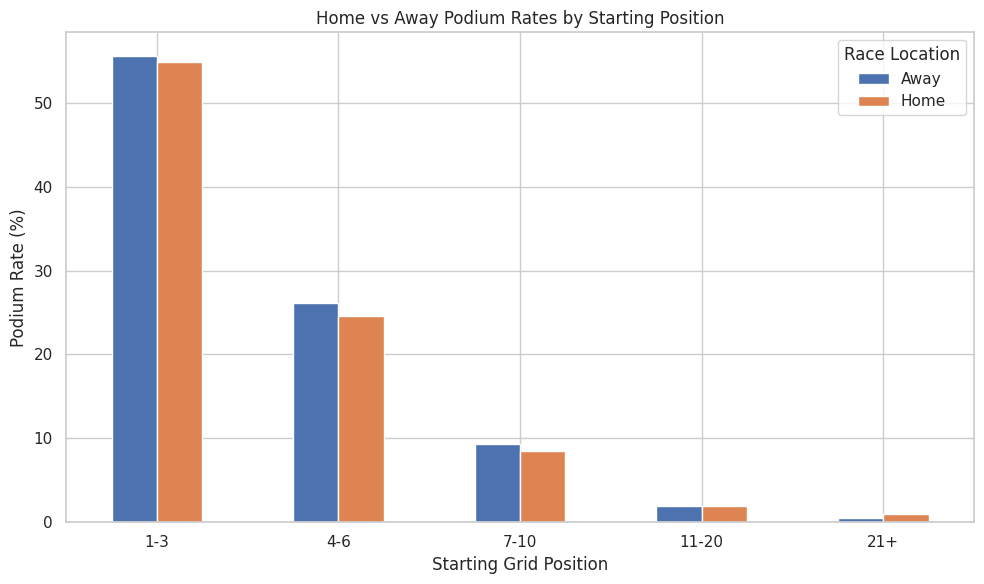

In [39]:
# Arrange home and away podium rates side by side.
home_grid_plot = grid_home_comparison.pivot(
    index="grid_group",
    columns="Location",
    values="podium_rate"
)

# Create a bar chart.
home_grid_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.xlabel("Starting Grid Position")
plt.ylabel("Podium Rate (%)")
plt.title("Home vs Away Podium Rates by Starting Position")
plt.xticks(rotation=0)
plt.legend(title="Race Location")
plt.tight_layout()
plt.show()

In [40]:
# Compare home and away rates within each grid group.
home_advantage = home_grid_plot.copy()

# Calculate the difference in percentage points.
home_advantage["Home Advantage"] = (
    home_advantage["Home"]
    - home_advantage["Away"]
)

# Show the comparison.
display(home_advantage.round(2))

Location,Away,Home,Home Advantage
grid_group,,,
1-3,55.62,54.83,-0.79
4-6,26.15,24.61,-1.54
7-10,9.28,8.44,-0.84
11-20,1.97,1.88,-0.09
21+,0.49,0.93,0.44


### 2.2.1 Findings

The results suggest that racing at home does not provide a clear podium advantage once starting position is considered.

Drivers starting in positions 1–3 have the highest podium rates, while those starting further back have much lower chances. Within most grid groups, the differences between home and away drivers are small.

Overall, starting position appears to be more important than home-country advantage. However, other factors, such as driver skill and car performance, may also influence the results.

### 2.3 Mechanical Retirement Rates by Constructor

We compare mechanical retirement rates between 2014–2021 and 2022–2024. We first examine the recorded retirement reasons to identify mechanical failures and exclude unrelated causes.

In [42]:
# Display all recorded race statuses.
status_list = clean_tables["status"].copy()

display(
    status_list.sort_values("statusId")
)

,statusId,status
0,1,Finished
1,2,Disqualified
2,3,Accident
3,4,Collision
4,5,Engine
...,...,...
134,137,Damage
135,138,Debris
136,139,Illness
137,140,Undertray


In [44]:
# Select races from 2014 to 2024.
mechanical_data = results_driver_race.merge(
    clean_tables["races"][["raceId", "year"]],
    on="raceId",
    how="left",
    validate="many_to_one"
)

mechanical_data = mechanical_data[
    mechanical_data["year"].between(2014, 2024)
].copy()

# Add the recorded retirement reasons.
mechanical_data = mechanical_data.merge(
    clean_tables["status"][["statusId", "status"]],
    on="statusId",
    how="left",
    validate="many_to_one"
)

# Count each retirement reason.
status_counts = (
    mechanical_data["status"]
    .value_counts()
    .reset_index()
)

status_counts.columns = ["Status", "Count"]

display(status_counts)

,Status,Count
0,Finished,2403
1,+1 Lap,1178
2,+2 Laps,208
3,Collision,150
4,Accident,85
...,...,...
61,Water pump,1
62,Cooling system,1
63,Fuel pump,1
64,Differential,1


In [48]:
# Define mechanical failure reasons.
mechanical_statuses = [
    "Engine",
    "Gearbox",
    "Transmission",
    "Hydraulics",
    "Brakes",
    "Suspension",
    "Electrical",
    "Electronics",
    "Power Unit",
    "Battery",
    "Fuel system",
    "Fuel pump",
    "Clutch",
    "Turbo",
    "Cooling system",
    "Overheating",
    "Radiator",
    "Water leak",
    "Oil leak",
    "Oil pressure",
    "Exhaust",
    "Driveshaft",
    "Differential",
    "Wheel bearing",
    "Alternator",
    "Injection"
]

# Flag mechanical retirements.
mechanical_data["mechanical_retirement"] = (
    mechanical_data["status"].isin(mechanical_statuses)
)

# Check the classification.
print("Mechanical retirements identified:",
      mechanical_data["mechanical_retirement"].sum())

# Show which mechanical failures occurred.
display(
    mechanical_data.loc[
        mechanical_data["mechanical_retirement"],
        "status"
    ].value_counts().to_frame("Count")
)

# Check which selected status labels exist in the dataset.
print("\nSelected labels not found in the status table:")
print(sorted(set(mechanical_statuses) -
             set(clean_tables["status"]["status"])))

Mechanical retirements identified: 326


,Count
status,
Engine,81
Brakes,49
Power Unit,42
Gearbox,42
Suspension,25
Hydraulics,15
Electrical,14
Oil leak,10
Overheating,8



Selected labels not found in the status table:
[]


In [49]:
# Identify statuses that clearly indicate no race start.
non_start_statuses = [
    "Did not start",
    "Did not qualify",
    "Did not prequalify",
    "Withdrew"
]

# Flag records with a confirmed non-start status.
mechanical_data["confirmed_non_start"] = (
    mechanical_data["status"].isin(non_start_statuses)
)

# Inspect zero-grid entries separately.
zero_grid_review = (
    mechanical_data.loc[
        mechanical_data["grid"] == 0,
        ["year", "status", "confirmed_non_start"]
    ]
    .groupby(["status", "confirmed_non_start"])
    .size()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
)

print("Confirmed non-start entries:",
      mechanical_data["confirmed_non_start"].sum())

print("\nZero-grid status breakdown:")
display(zero_grid_review)

Confirmed non-start entries: 14

Zero-grid status breakdown:


,status,confirmed_non_start,Count
0,+1 Lap,False,27
8,Finished,False,22
1,+2 Laps,False,7
6,Collision damage,False,3
17,Withdrew,True,3
2,Accident,False,2
13,Retired,False,2
12,Power Unit,False,2
4,Brakes,False,2
5,Collision,False,1


In [56]:
# Exclude confirmed non-starters.
mechanical_starters = mechanical_data[
    ~mechanical_data["confirmed_non_start"]
].copy()

# Check that every mechanical retirement is included.
assert mechanical_starters.loc[
    mechanical_starters["mechanical_retirement"]
].shape[0] == mechanical_data["mechanical_retirement"].sum()

# Add constructor names.
mechanical_starters = mechanical_starters.merge(
    clean_tables["constructors"][["constructorId", "name"]],
    on="constructorId",
    how="left",
    validate="many_to_one"
)

# Separate the two racing eras.
mechanical_starters["era"] = np.where(
    mechanical_starters["year"] <= 2021,
    "2014-2021",
    "2022-2024"
)

# Calculate mechanical retirements and race starts.
constructor_retirement_rates = (
    mechanical_starters
    .groupby(["name", "era"])
    .agg(
        race_starts=("raceId", "size"),
        mechanical_retirements=("mechanical_retirement", "sum")
    )
    .reset_index()
)

# Calculate retirement percentages.
constructor_retirement_rates["retirement_rate"] = (
    constructor_retirement_rates["mechanical_retirements"]
    / constructor_retirement_rates["race_starts"] * 100
)

display(
    constructor_retirement_rates.sort_values(
        ["era", "retirement_rate"],
        ascending=[True, False]
    ).round(2)
)

,name,era,race_starts,mechanical_retirements,retirement_rate
8,Caterham,2014-2021,34,8,23.53
14,Lotus F1,2014-2021,75,13,17.33
28,Toro Rosso,2014-2021,242,39,16.12
17,McLaren,2014-2021,318,43,13.52
25,Renault,2014-2021,200,27,13.50
26,Sauber,2014-2021,200,22,11.00
23,Red Bull,2014-2021,319,33,10.34
2,AlphaTauri,2014-2021,78,8,10.26
16,Marussia,2014-2021,31,3,9.68
22,Racing Point,2014-2021,76,7,9.21


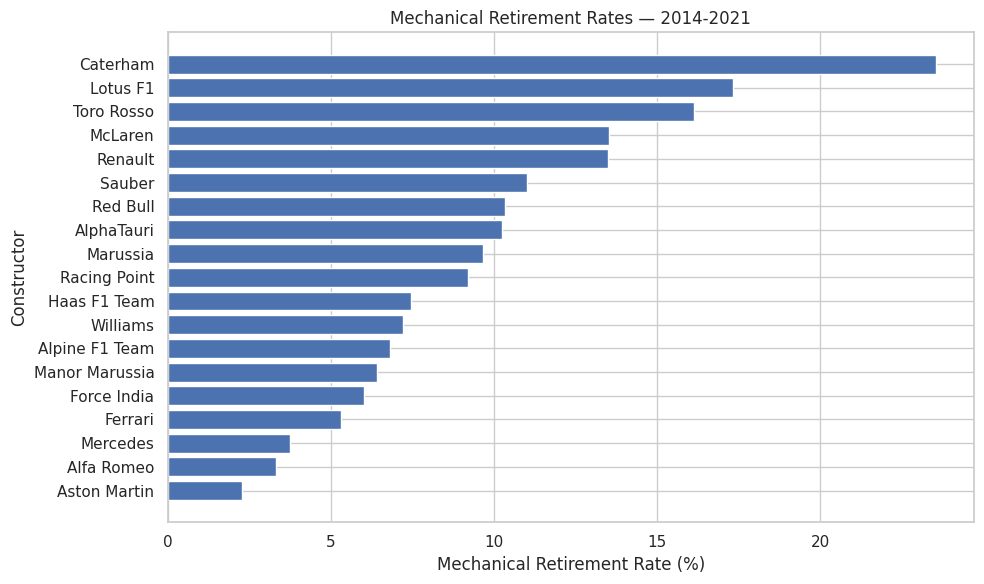

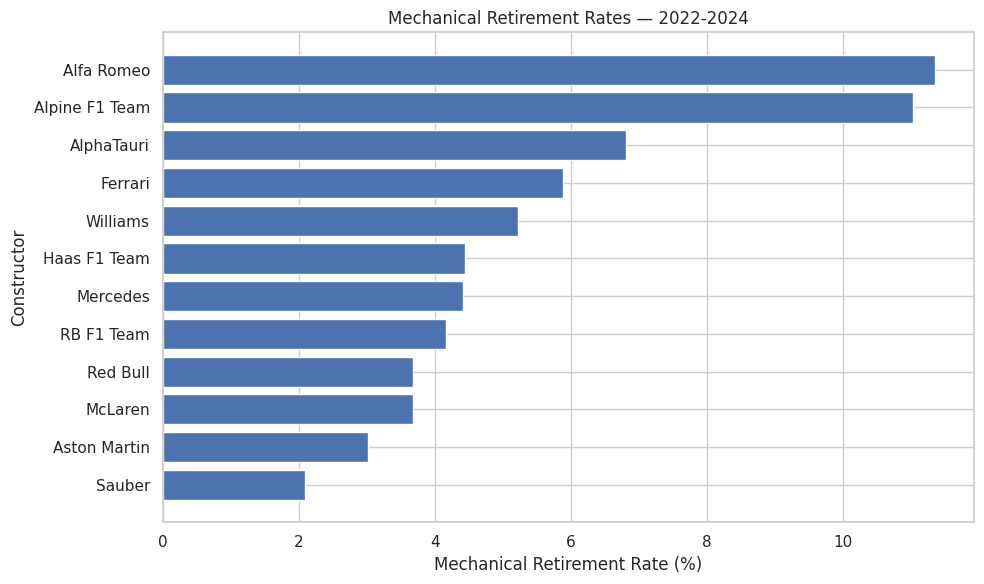

In [57]:
# Select constructors with at least 20 recorded starts in an era.
plot_data = constructor_retirement_rates[
    constructor_retirement_rates["race_starts"] >= 20
].copy()

# Sort constructors by retirement rate.
plot_data = plot_data.sort_values(
    ["era", "retirement_rate"],
    ascending=[True, False]
)

# Create two graphs, one for each era.
for era in ["2014-2021", "2022-2024"]:

    era_data = plot_data[
        plot_data["era"] == era
    ].sort_values("retirement_rate")

    plt.figure(figsize=(10, 6))

    plt.barh(
        era_data["name"],
        era_data["retirement_rate"]
    )

    plt.xlabel("Mechanical Retirement Rate (%)")
    plt.ylabel("Constructor")
    plt.title(f"Mechanical Retirement Rates — {era}")
    plt.tight_layout()
    plt.show()

In [59]:
# Display the top 5 constructors for each era.
for era in ["2014-2021", "2022-2024"]:

    top_5 = (
        constructor_retirement_rates[
            (constructor_retirement_rates["era"] == era) &
            (constructor_retirement_rates["race_starts"] >= 20)
        ]
        .sort_values("retirement_rate", ascending=False)
        .head(5)
    )

    print(f"\nTop 5 Constructors: {era}")

    display(
        top_5[
            ["name", "race_starts",
             "mechanical_retirements", "retirement_rate"]
        ].round(2)
    )


Top 5 Constructors: 2014-2021


,name,race_starts,mechanical_retirements,retirement_rate
8,Caterham,34,8,23.53
14,Lotus F1,75,13,17.33
28,Toro Rosso,242,39,16.12
17,McLaren,318,43,13.52
25,Renault,200,27,13.50



Top 5 Constructors: 2022-2024


,name,race_starts,mechanical_retirements,retirement_rate
1,Alfa Romeo,88,10,11.36
5,Alpine F1 Team,136,15,11.03
3,AlphaTauri,88,6,6.82
10,Ferrari,136,8,5.88
30,Williams,134,7,5.22


In [53]:
# Find statuses not classified as mechanical failures.
unclassified_statuses = (
    mechanical_data[
        ~mechanical_data["mechanical_retirement"]
        & ~mechanical_data["confirmed_non_start"]
    ]
    .groupby("status")
    .size()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
)

# Display all remaining statuses.
display(unclassified_statuses)

,status,Count
18,Finished,2403
0,+1 Lap,1178
1,+2 Laps,208
10,Collision,150
8,Accident,85
11,Collision damage,59
28,Retired,50
2,+3 Laps,24
25,Power loss,13
14,Disqualified,11


In [54]:
# Add the missing mechanical failure statuses.
additional_mechanical_statuses = [
    "Fuel leak",
    "Steering",
    "Throttle",
    "Spark plugs",
    "Water pump",
    "Brake duct",
    "Drivetrain",
    "Power loss",
    "Mechanical",
    "Water pressure",
    "ERS",
    "Fuel pressure"
]

# Update the mechanical failure list.
mechanical_statuses = list(
    set(mechanical_statuses + additional_mechanical_statuses)
)

# Update the classification.
mechanical_data["mechanical_retirement"] = (
    mechanical_data["status"].isin(mechanical_statuses)
)

print("Total mechanical retirements:",
      mechanical_data["mechanical_retirement"].sum())

display(
    mechanical_data.loc[
        mechanical_data["mechanical_retirement"],
        "status"
    ].value_counts().to_frame("Count")
)

Total mechanical retirements: 373


,Count
status,
Engine,81
Brakes,49
Power Unit,42
Gearbox,42
Suspension,25
Hydraulics,15
Electrical,14
Power loss,13
Oil leak,10


In [60]:
# Check statuses that may represent non-starters.
start_review = mechanical_data[
    mechanical_data["status"].str.contains(
        "start|qualif|withdr|prequalif",
        case=False,
        na=False
    )
].groupby(["status", "confirmed_non_start"]).size()

display(start_review.to_frame("Count"))

,,Count
status,confirmed_non_start,
Disqualified,False,11
Withdrew,True,14


In [61]:
display(start_review.to_frame("Count"))

,,Count
status,confirmed_non_start,
Disqualified,False,11
Withdrew,True,14


### 2.3.1 Findings

The analysis compared mechanical retirement rates across constructors in two periods: 2014–2021 and 2022–2024.

During 2014–2021, Caterham had the highest mechanical retirement rate at approximately 23.5%, followed by Lotus F1 at 17.3% and Toro Rosso at 16.1%.

During 2022–2024, Alfa Romeo had the highest rate at approximately 11.3%, followed by Alpine F1 Team at 11.0% and AlphaTauri at 6.8%.

The results suggest that the highest mechanical retirement rates were lower in the second period. However, this does not necessarily mean that the regulation changes caused the improvement, since other factors may have influenced reliability.

### 2.4 Feature Engineering

We create features to predict whether a driver will finish on the podium.

Only information available before the race is used as input. This prevents data leakage and allows the model to make realistic pre-race predictions.

In [65]:
# Start with results from 2003 to 2024.
model_data = results_driver_race.merge(
    clean_tables["races"][
        ["raceId", "year", "round", "circuitId", "date"]
    ],
    on="raceId",
    how="left",
    validate="many_to_one"
)

# Keep the selected years and unambiguous records.
model_data = model_data[
    model_data["year"].between(2003, 2024)
    & ~model_data["ambiguous_driver_race"]
].copy()

# Arrange races chronologically.
model_data = model_data.sort_values(
    ["date", "raceId", "driverId"]
).reset_index(drop=True)

print("Total records:", len(model_data))
print("Years:", model_data["year"].min(),
      "-", model_data["year"].max())

display(
    model_data[
        ["year", "round", "driverId",
         "constructorId", "grid_position", "podium"]
    ].head(10)
)

Total records: 8970
Years: 2003 - 2024


,year,round,driverId,constructorId,grid_position,podium
0,2003,1,2,15,7.0,0
1,2003,1,4,4,10.0,0
2,2003,1,8,1,15.0,1
3,2003,1,14,1,11.0,1
4,2003,1,15,4,12.0,0
5,2003,1,17,19,14.0,0
6,2003,1,18,16,8.0,0
7,2003,1,21,17,13.0,0
8,2003,1,22,6,2.0,0
9,2003,1,23,3,9.0,0


In [68]:
# Count each driver's previous race entries.
model_data["driver_experience"] = (
    model_data.groupby("driverId").cumcount()
)

# Display the results.
display(
    model_data[
        ["year", "driverId", "grid_position",
         "driver_experience", "podium"]
    ].head(15)
)

# Check the feature.
print("Minimum experience:", model_data["driver_experience"].min())
print("Maximum experience:", model_data["driver_experience"].max())

,year,driverId,grid_position,driver_experience,podium
0,2003,2,7.0,0,0
1,2003,4,10.0,0,0
2,2003,8,15.0,0,1
3,2003,14,11.0,0,1
4,2003,15,12.0,0,0
5,2003,17,14.0,0,0
6,2003,18,8.0,0,0
7,2003,21,13.0,0,0
8,2003,22,2.0,0,0
9,2003,23,9.0,0,0


Minimum experience: 0
Maximum experience: 386


In [69]:
# Calculate podium rate over each driver's previous 5 races.
model_data["driver_recent_podium_rate"] = (
    model_data.groupby("driverId")["podium"]
    .transform(
        lambda x: x.shift(1).rolling(
            window=5, min_periods=1
        ).mean()
    )
)

# Display the results.
display(
    model_data[
        ["year", "driverId", "driver_experience",
         "driver_recent_podium_rate", "podium"]
    ].tail(15)
)

print(
    "Missing recent podium rates:",
    model_data["driver_recent_podium_rate"].isna().sum()
)

,year,driverId,driver_experience,driver_recent_podium_rate,podium
8955,2024,825,185,0.0,0
8956,2024,830,208,0.6,0
8957,2024,832,207,0.6,1
8958,2024,840,167,0.0,0
8959,2024,842,153,0.2,0
8960,2024,844,148,0.6,1
8961,2024,846,127,0.2,1
8962,2024,847,127,0.2,0
8963,2024,848,104,0.0,0
8964,2024,852,89,0.0,0


Missing recent podium rates: 113


In [70]:
# Calculate constructor podium rate for each race.
constructor_race = (
    model_data.groupby(["constructorId", "raceId", "date"])
    .agg(
        podiums=("podium", "sum"),
        entries=("podium", "size")
    )
    .reset_index()
)

# Sort races chronologically for each constructor.
constructor_race = constructor_race.sort_values(
    ["constructorId", "date", "raceId"]
)

# Calculate podium rate over the previous 5 races.
constructor_race["constructor_recent_podium_rate"] = (
    constructor_race.groupby("constructorId")["podiums"]
    .transform(lambda x: x.shift(1).rolling(5, min_periods=1).sum())
    /
    constructor_race.groupby("constructorId")["entries"]
    .transform(lambda x: x.shift(1).rolling(5, min_periods=1).sum())
)

# Add the feature to our modeling dataset.
model_data = model_data.merge(
    constructor_race[
        ["constructorId", "raceId", "constructor_recent_podium_rate"]
    ],
    on=["constructorId", "raceId"],
    how="left",
    validate="many_to_one"
)

display(
    model_data[
        ["year", "constructorId", "driverId",
         "constructor_recent_podium_rate", "podium"]
    ].tail(15)
)

print(
    "Missing constructor rates:",
    model_data["constructor_recent_podium_rate"].isna().sum()
)

,year,constructorId,driverId,constructor_recent_podium_rate,podium
8955,2024,210,825,0.0,0
8956,2024,9,830,0.3,0
8957,2024,6,832,0.6,1
8958,2024,117,840,0.0,0
8959,2024,214,842,0.2,0
8960,2024,6,844,0.6,1
8961,2024,1,846,0.2,1
8962,2024,131,847,0.2,0
8963,2024,3,848,0.0,0
8964,2024,215,852,0.0,0


Missing constructor rates: 70


In [71]:
# Add driver nationality.
model_data = model_data.merge(
    clean_tables["drivers"][["driverId", "nationality"]],
    on="driverId",
    how="left",
    validate="many_to_one"
)

# Add the circuit's country.
model_data = model_data.merge(
    clean_tables["circuits"][["circuitId", "country"]],
    on="circuitId",
    how="left",
    validate="many_to_one"
)

# Convert nationality into country.
model_data["driver_country"] = (
    model_data["nationality"].map(nationality_to_country)
)

# Identify home races.
# Keep unknown nationalities as missing rather than calling them away races.
model_data["home_race"] = (
    model_data["driver_country"] == model_data["country"]
).astype(float)

model_data.loc[
    model_data["driver_country"].isna() | model_data["country"].isna(),
    "home_race"
] = np.nan

# Display results.
display(
    model_data[
        ["year", "driverId", "circuitId",
         "nationality", "country", "home_race"]
    ].head(15)
)

print("Missing home-race values:",
      model_data["home_race"].isna().sum())

,year,driverId,circuitId,nationality,country,home_race
0,2003,2,1,German,Australia,0.0
1,2003,4,1,Spanish,Australia,0.0
2,2003,8,1,Finnish,Australia,0.0
3,2003,14,1,British,Australia,0.0
4,2003,15,1,Italian,Australia,0.0
5,2003,17,1,Australian,Australia,1.0
6,2003,18,1,British,Australia,0.0
7,2003,21,1,Italian,Australia,0.0
8,2003,22,1,Brazilian,Australia,0.0
9,2003,23,1,German,Australia,0.0


Missing home-race values: 126


In [72]:
# Select the features used for prediction.
feature_columns = [
    "grid_position",
    "driver_experience",
    "driver_recent_podium_rate",
    "constructor_recent_podium_rate",
    "circuitId",
    "home_race"
]

# Prepare the modeling dataset.
model_dataset = model_data[
    ["raceId", "year", "date", "driverId",
     "constructorId"] + feature_columns + ["podium"]
].copy()

# Display the selected features.
display(model_dataset.head(10))

print("Dataset shape:", model_dataset.shape)
print("\nMissing values:")
print(model_dataset[feature_columns].isna().sum())

,raceId,year,date,driverId,constructorId,grid_position,driver_experience,driver_recent_podium_rate,constructor_recent_podium_rate,circuitId,home_race,podium
0,108,2003,2003-03-09,2,15,7.0,0,NaN,NaN,1,0.0,0
1,108,2003,2003-03-09,4,4,10.0,0,NaN,NaN,1,0.0,0
2,108,2003,2003-03-09,8,1,15.0,0,NaN,NaN,1,0.0,1
3,108,2003,2003-03-09,14,1,11.0,0,NaN,NaN,1,0.0,1
4,108,2003,2003-03-09,15,4,12.0,0,NaN,NaN,1,0.0,0
5,108,2003,2003-03-09,17,19,14.0,0,NaN,NaN,1,1.0,0
6,108,2003,2003-03-09,18,16,8.0,0,NaN,NaN,1,0.0,0
7,108,2003,2003-03-09,21,17,13.0,0,NaN,NaN,1,0.0,0
8,108,2003,2003-03-09,22,6,2.0,0,NaN,NaN,1,0.0,0
9,108,2003,2003-03-09,23,3,9.0,0,NaN,NaN,1,0.0,0


Dataset shape: (8970, 12)

Missing values:
grid_position                      86
driver_experience                   0
driver_recent_podium_rate         113
constructor_recent_podium_rate     70
circuitId                           0
home_race                         126
dtype: int64


### 2.5 Chronological Train/Validation/Test Split

We split the dataset chronologically to simulate real-world predictions.

Training uses races from 2003–2018, validation uses 2019–2021, and testing uses 2022–2024.

This ensures that the model is trained on earlier races and evaluated on later races, avoiding future information leakage during training.

In [73]:
# Split the data chronologically by year.
train_data = model_dataset[
    model_dataset["year"] <= 2018
].copy()

val_data = model_dataset[
    model_dataset["year"].between(2019, 2021)
].copy()

test_data = model_dataset[
    model_dataset["year"].between(2022, 2024)
].copy()

# Display the size and podium rate of each dataset.
split_summary = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Testing"],
    "Start Year": [
        train_data["year"].min(),
        val_data["year"].min(),
        test_data["year"].min()
    ],
    "End Year": [
        train_data["year"].max(),
        val_data["year"].max(),
        test_data["year"].max()
    ],
    "Rows": [
        len(train_data),
        len(val_data),
        len(test_data)
    ],
    "Podium Rate (%)": [
        train_data["podium"].mean() * 100,
        val_data["podium"].mean() * 100,
        test_data["podium"].mean() * 100
    ]
})

display(split_summary.round(2))

# Verify that every record belongs to exactly one split.
assert len(train_data) + len(val_data) + len(test_data) == len(model_dataset)

,Dataset,Start Year,End Year,Rows,Podium Rate (%)
0,Training,2003,2018,6411,14.04
1,Validation,2019,2021,1200,15.00
2,Testing,2022,2024,1359,15.01


In [74]:
# Separate input features and target for each dataset.
X_train = train_data[feature_columns].copy()
y_train = train_data["podium"].copy()

X_val = val_data[feature_columns].copy()
y_val = val_data["podium"].copy()

X_test = test_data[feature_columns].copy()
y_test = test_data["podium"].copy()

# Check the dimensions.
print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

# Preview the training features.
display(X_train.head())

Training: (6411, 6) (6411,)
Validation: (1200, 6) (1200,)
Testing: (1359, 6) (1359,)


,grid_position,driver_experience,driver_recent_podium_rate,constructor_recent_podium_rate,circuitId,home_race
0,7.0,0,NaN,NaN,1,0.0
1,10.0,0,NaN,NaN,1,0.0
2,15.0,0,NaN,NaN,1,0.0
3,11.0,0,NaN,NaN,1,0.0
4,12.0,0,NaN,NaN,1,0.0


In [75]:
# Check chronological order.
assert train_data["year"].max() < val_data["year"].min()
assert val_data["year"].max() < test_data["year"].min()

# Check that no race appears in multiple datasets.
assert set(train_data["raceId"]).isdisjoint(val_data["raceId"])
assert set(train_data["raceId"]).isdisjoint(test_data["raceId"])
assert set(val_data["raceId"]).isdisjoint(test_data["raceId"])

# Check that the target is not included in the input features.
assert "podium" not in feature_columns
assert "positionOrder" not in feature_columns
assert "statusId" not in feature_columns

# Check for duplicate driver-race records.
assert not model_dataset.duplicated(
    subset=["raceId", "driverId"]
).any()

# Check that all target values are binary.
assert set(model_dataset["podium"].unique()).issubset({0, 1})

# Check that all datasets have the same input features.
assert list(X_train.columns) == feature_columns
assert list(X_val.columns) == feature_columns
assert list(X_test.columns) == feature_columns

print("All dataset consistency checks passed!")
print("Training records:", len(X_train))
print("Validation records:", len(X_val))
print("Testing records:", len(X_test))

All dataset consistency checks passed!
Training records: 6411
Validation records: 1200
Testing records: 1359


### 2.6 Modeling Dataset Handover

The dataset is ready for the modeling stage.

We created six pre-race features:
1. Grid position
2. Driver experience
3. Driver podium rate over the previous five races
4. Constructor podium rate over the previous five races
5. Circuit ID
6. Home-race indicator

The target variable is `podium`, where 1 represents a podium finish and 0 represents any other result.

The data was divided chronologically:
- Training: 2003–2018
- Validation: 2019–2021
- Testing: 2022–2024

The following variables are available for modeling:
- `X_train`, `y_train`
- `X_val`, `y_val`
- `X_test`, `y_test`

Preprocessing, including missing-value imputation, feature encoding, and scaling, will be handled in the modeling section. Preprocessing parameters must be learned from training data only.

The historical performance features use previous race results to avoid including the current race outcome.

Dataset consistency checks should be completed before model training.

In [76]:
# Final handover verification
required_variables = [
    "X_train", "y_train",
    "X_val", "y_val",
    "X_test", "y_test"
]

for variable in required_variables:
    assert variable in globals(), f"Missing variable: {variable}"

# Check that features and targets have matching row counts.
assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)
assert len(X_test) == len(y_test)

# Check that no split is empty.
assert min(len(X_train), len(X_val), len(X_test)) > 0

print("Handover variables verified successfully!")
print(f"Training: {X_train.shape}")
print(f"Validation: {X_val.shape}")
print(f"Testing: {X_test.shape}")

Handover variables verified successfully!
Training: (6411, 6)
Validation: (1200, 6)
Testing: (1359, 6)
